# Figure S16B — amino-acid composition of human transcription factors and their IDRs

Fraction of each amino acid in, left to right: the human proteome, all human-proteome IDRs, all human transcription factors, and transcription-factor IDRs. Transcription factors are enriched in K, C and H (DNA-binding domains), but transcription-factor IDRs are compositionally close to IDRs proteome-wide.

**How it is made.** IDRs come from `HP_IDRs.tsv` and `TF_IDRs.tsv` in `data/human_transcription_factors/` (shared data directory), written by `build_idr_tables.py` (metapredict 3.1.0, V3); sequences from the UniProt FASTA files in the same directory.

**Output:** `figures/figure_S16B.pdf`

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from figtools import XMGRACE_COLORS, apply_style, require_metapredict_3_1, save_panel
from tf_idrs import AMINO_ACIDS, composition, load_set

require_metapredict_3_1()
apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

TFs, TF_idrs = load_set('tfs')
HP, HP_idrs = load_set('proteome')

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
sets = {'Human proteome': composition(HP),
        'Human IDRs': composition(HP, HP_idrs),
        'Human TFs': composition(TFs),
        'Human TF IDRs': composition(TFs, TF_idrs)}

Wrote figures/figure_S16B.pdf


PosixPath('figures/figure_S16B.pdf')

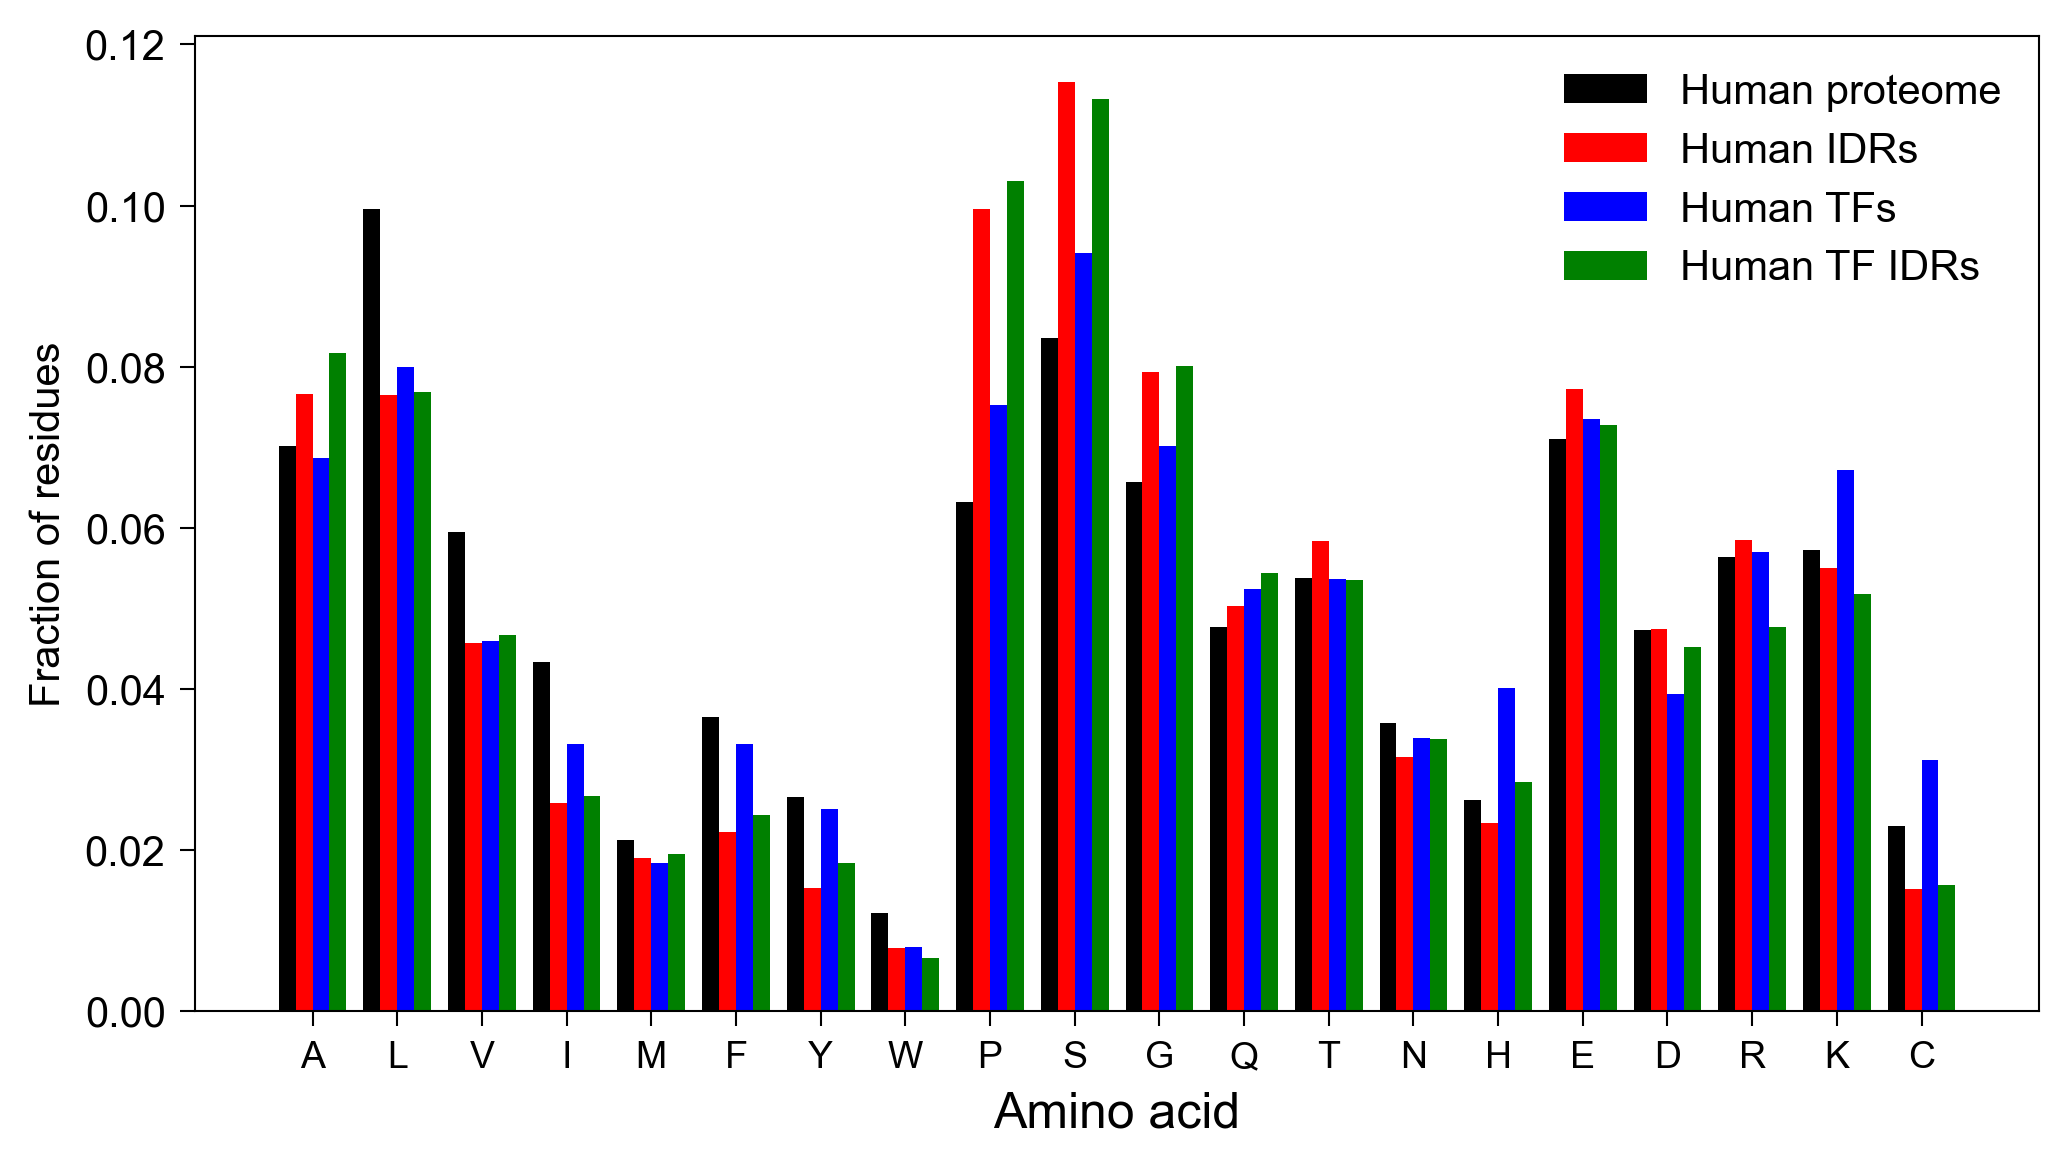

In [3]:
x = np.arange(len(AMINO_ACIDS))
bar_width = 0.2
offsets = [-1.5, -0.5, 0.5, 1.5]

fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
for (label, comp), offset, color in zip(sets.items(), offsets, XMGRACE_COLORS):
    ax.bar(x + offset * bar_width, [comp[aa] for aa in AMINO_ACIDS], width=bar_width, label=label, color=color)
ax.set_xticks(x, AMINO_ACIDS, fontsize=9)
ax.set_xlabel('Amino acid', fontsize=12)
ax.set_ylabel('Fraction of residues')
ax.legend()
plt.tight_layout()
save_panel(fig, 'figure_S16B')